# Voyage Analytics — 02. User Gender Classification

## Project Overview
This notebook investigates `users.csv`, diagnoses the `"none"` gender labels statistically, and builds a lightweight, leakage-free **binary (`male` vs `female`) classification pipeline** for the **Voyage Analytics** MLOps Capstone Project.

### Objectives
1. Audit `users.csv` (1,340 user profiles) for data quality, duplicates, and class balance.
2. **Investigate `"none"` gender values** using statistical tests (Chi-square, ANOVA) and name overlap to prove they represent undisclosed/missing labels rather than a predictable third gender class.
3. Visualize user demographics and linguistic first-name patterns via Exploratory Data Analysis (EDA).
4. Engineer deterministic linguistic features and construct a leakage-free `scikit-learn` pipeline.
5. Compare five classification algorithms (**Logistic Regression, Calibrated LinearSVC, Random Forest, LightGBM, XGBoost**) using **5-fold Stratified Cross-Validation** and an 80/20 stratified holdout set.
6. Report **Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Confusion Matrices** (plus an unseen first-name generalization audit).
7. Save a **lightweight, portable model artifact** (`models/gender_classifier.joblib`, < 200 KB—avoiding the fragile 92 MB pickled `SentenceTransformer` bundle).

## 1. Environment & Google Colab Compatibility Setup

In [1]:
# Optional: Uncomment when running in Google Colab if packages are missing.
# !pip install -q lightgbm xgboost scikit-learn pandas numpy scipy matplotlib seaborn joblib

import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)

IN_COLAB = "google.colab" in sys.modules
print(f"Running in Google Colab: {IN_COLAB}")
print(f"Python {sys.version.split()[0]} | Pandas {pd.__version__} | NumPy {np.__version__}")

Running in Google Colab: False
Python 3.13.14 | Pandas 3.1.1 | NumPy 2.5.5


In [2]:
def resolve_project_paths(dataset_filename: str = "users.csv"):
    """Locate the project root and dataset path across local Jupyter and Google Colab."""
    cwd = Path.cwd()
    candidates = [
        cwd,
        cwd.parent,
        Path("/content"),
        Path("/content/voyage-analytics-mlops"),
        Path("/content/drive/MyDrive/voyage-analytics-mlops"),
    ]
    for base in candidates:
        data_file = base / "travel_capstone_dataset" / dataset_filename
        if data_file.exists():
            return base, data_file

    direct_colab = Path("/content") / dataset_filename
    if direct_colab.exists():
        return Path("/content"), direct_colab

    raise FileNotFoundError(
        f"Could not locate '{dataset_filename}'. In Google Colab, upload "
        "'travel_capstone_dataset/users.csv' to /content/travel_capstone_dataset/."
    )

PROJECT_ROOT, USERS_PATH = resolve_project_paths("users.csv")
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
GENDER_MODEL_PATH = MODELS_DIR / "gender_classifier.joblib"

print("Dataset file found :", USERS_PATH.name, "| Exists:", USERS_PATH.exists())
print("Model output target:", GENDER_MODEL_PATH.relative_to(PROJECT_ROOT))

Dataset file found : users.csv | Exists: True
Model output target: models\gender_classifier.joblib


## 2. Data Loading & Integrity Verification

In [3]:
users = pd.read_csv(USERS_PATH)

print(f"Dataset shape  : {users.shape[0]:,} rows x {users.shape[1]} columns")
print(f"Duplicate rows : {users.duplicated().sum()}")
print(f"Standard NaNs  : {int(users.isnull().sum().sum())}")
print("\nSchema:")
users.info()
display(users.head(10))

Dataset shape  : 1,340 rows x 5 columns
Duplicate rows : 0
Standard NaNs  : 0

Schema:
<class 'pandas.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   code     1340 non-null   int64
 1   company  1340 non-null   str  
 2   name     1340 non-null   str  
 3   gender   1340 non-null   str  
 4   age      1340 non-null   int64
dtypes: int64(2), str(3)
memory usage: 88.3 KB


,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44
5,5,4You,Trina Thomas,none,47
6,6,4You,Jesse Decelle,male,46
7,7,4You,Gregoria Gil,female,21
8,8,4You,Jack Sabo,none,41
9,9,4You,Debbie Helms,none,35


## 3. Investigating the `"none"` Gender Values
Although `users.isnull().sum()` shows `0` standard `NaN` values, inspecting `users["gender"].value_counts()` reveals **440 rows (32.84%)** containing the literal string `"none"`.

Before choosing a modeling formulation, we formally test whether `"none"` behaves like a distinct predictable user segment or like **undisclosed / Missing Completely At Random (MCAR) gender labels**:
1. **Company Independence (Chi-square test):** Does `"none"` concentrate in specific companies?
2. **Age Difference (One-Way ANOVA):** Do `"none"` users differ in age from `male`/`female` users?
3. **Name & Duplicate Evidence:** Do `"none"` users share identical full names and first names with clearly labeled `male` and `female` users?

In [4]:
gender_counts = users["gender"].value_counts(dropna=False)
gender_pct = (users["gender"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"count": gender_counts, "percent (%)": gender_pct}))

company_ct = pd.crosstab(users["company"], users["gender"])
chi2, p_chi2, _, _ = stats.chi2_contingency(company_ct)
print(f"\nChi-square test (company vs gender): chi2 = {chi2:.4f}, p-value = {p_chi2:.4f}")

age_groups = [grp["age"].values for _, grp in users.groupby("gender")]
f_stat, p_anova = stats.f_oneway(*age_groups)
print(f"One-way ANOVA (age across groups)  : F    = {f_stat:.4f}, p-value = {p_anova:.4f}")

users["first_name"] = users["name"].astype(str).str.strip().str.split().str[0].str.lower()
labeled_df = users[users["gender"].isin(["male", "female"])].copy().reset_index(drop=True)
undisclosed_df = users[users["gender"] == "none"].copy().reset_index(drop=True)

dup_names = users[users.duplicated("name", keep=False)].sort_values("name")
print("\nExact duplicate full names across gender labels:")
display(dup_names[["code", "company", "name", "gender", "age"]])

overlap_count = int(undisclosed_df["first_name"].isin(set(labeled_df["first_name"])).sum())
print(
    f"Undisclosed ('none') users sharing an exact first name with labeled users: "
    f"{overlap_count} / {len(undisclosed_df)} ({overlap_count / len(undisclosed_df) * 100:.1f}%)"
)
print(f"Duplicate full names within labeled set (male/female only): {labeled_df['name'].duplicated().sum()}")

,count,percent (%)
gender,,
male,452,33.73
female,448,33.43
none,440,32.84



Chi-square test (company vs gender): chi2 = 8.6243, p-value = 0.3750
One-way ANOVA (age across groups)  : F    = 0.4806, p-value = 0.6185

Exact duplicate full names across gender labels:


,code,company,name,gender,age
316,316,4You,Charlotte Johnson,female,64
496,496,Monsters CYA,Charlotte Johnson,none,51
309,309,4You,David Robinson,male,33
946,946,Acme Factory,David Robinson,none,30


Undisclosed ('none') users sharing an exact first name with labeled users: 294 / 440 (66.8%)
Duplicate full names within labeled set (male/female only): 0


### Conclusion on Handling `"none"` Gender Values
- **No company signal** ($p = 0.3750 > 0.05$) and **no age signal** ($p = 0.6185 > 0.05$).
- Exact full-name duplicates (`David Robinson`, `Charlotte Johnson`) appear once as `male`/`female` and once as `none`, and **66.8%** of `"none"` rows share an exact first name with labeled male/female records.
- **Modeling Decision:** Treating `"none"` as a third class introduces severe label noise (forcing the model to guess whether a name like *David Robinson* is `"male"` or `"none"`). Instead, we treat `"none"` as **undisclosed/missing labels**, hold those 440 rows out for optional post-training inference demonstration, and train a clean **binary `male` vs `female` classifier** on the **900 labeled records** (`452 male`, `448 female` — 50.2% / 49.8% balanced).

## 4. Exploratory Data Analysis (EDA)
We visualize raw vs labeled gender distributions, demographics by company and age, and linguistic first-name signals (ending letters and length) that motivate our lightweight feature design.

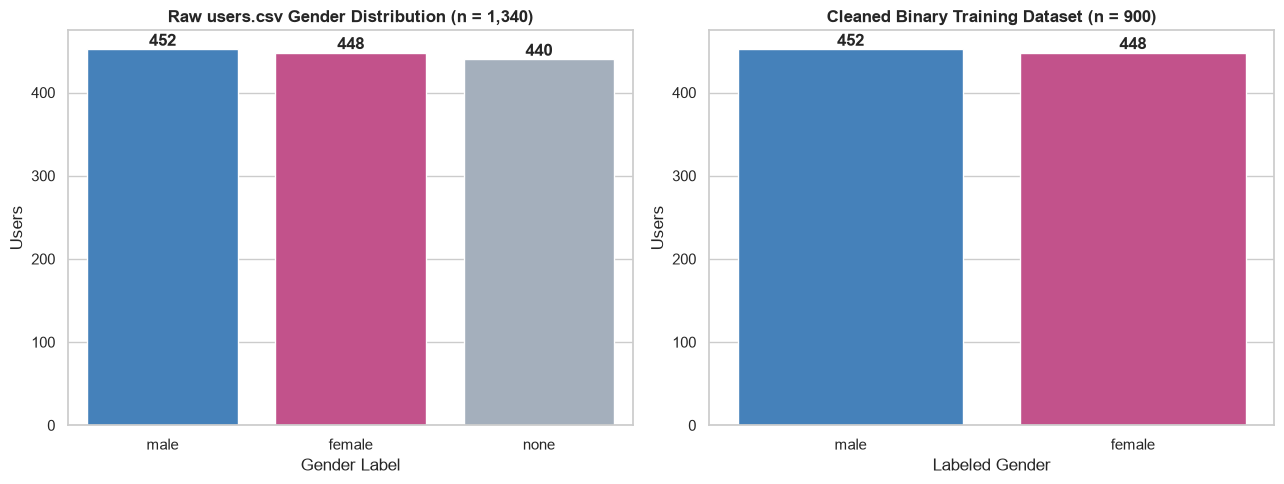

In [5]:
# Chart 1: Raw Dataset vs Clean Binary Labeled Subset
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

raw_counts = users["gender"].value_counts()
sns.barplot(x=raw_counts.index, y=raw_counts.values, palette=["#3182ce", "#d53f8c", "#a0aec0"], ax=axes[0])
axes[0].set_title("Raw users.csv Gender Distribution (n = 1,340)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Gender Label")
axes[0].set_ylabel("Users")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontweight="bold")

bin_counts = labeled_df["gender"].value_counts()
sns.barplot(x=bin_counts.index, y=bin_counts.values, palette=["#3182ce", "#d53f8c"], ax=axes[1])
axes[1].set_title("Cleaned Binary Training Dataset (n = 900)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Labeled Gender")
axes[1].set_ylabel("Users")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

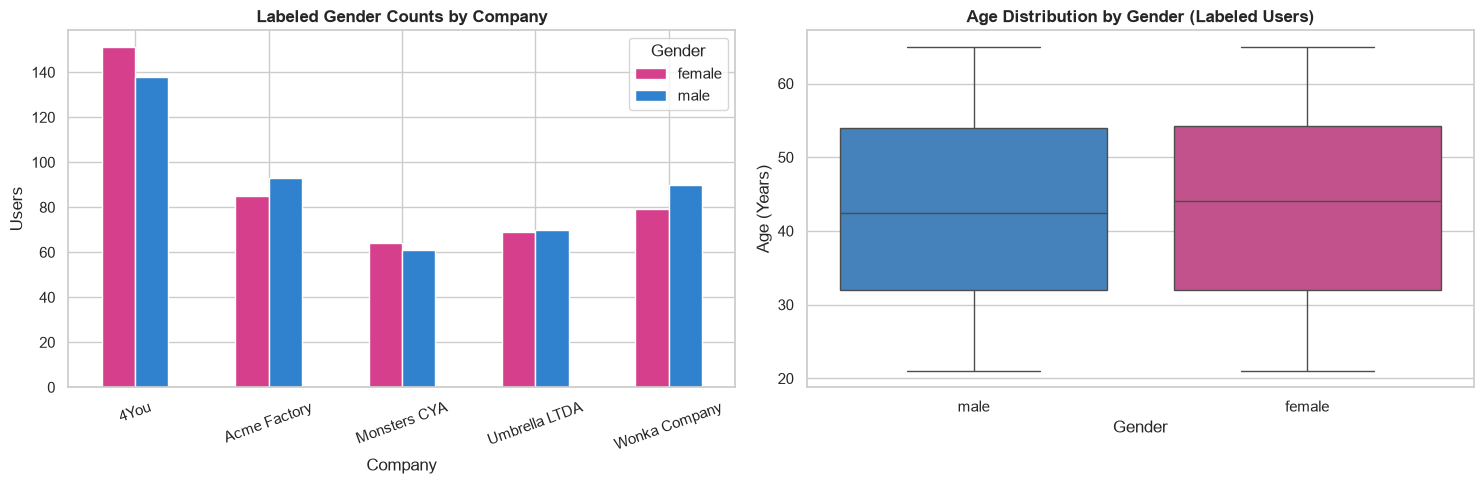

In [6]:
# Chart 2: Gender Distribution by Company and Age
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

company_bin = pd.crosstab(labeled_df["company"], labeled_df["gender"])
company_bin.plot(kind="bar", color=["#d53f8c", "#3182ce"], ax=axes[0])
axes[0].set_title("Labeled Gender Counts by Company", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Company")
axes[0].set_ylabel("Users")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="Gender")

sns.boxplot(data=labeled_df, x="gender", y="age", palette={"female": "#d53f8c", "male": "#3182ce"}, ax=axes[1])
axes[1].set_title("Age Distribution by Gender (Labeled Users)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Age (Years)")

plt.tight_layout()
plt.show()

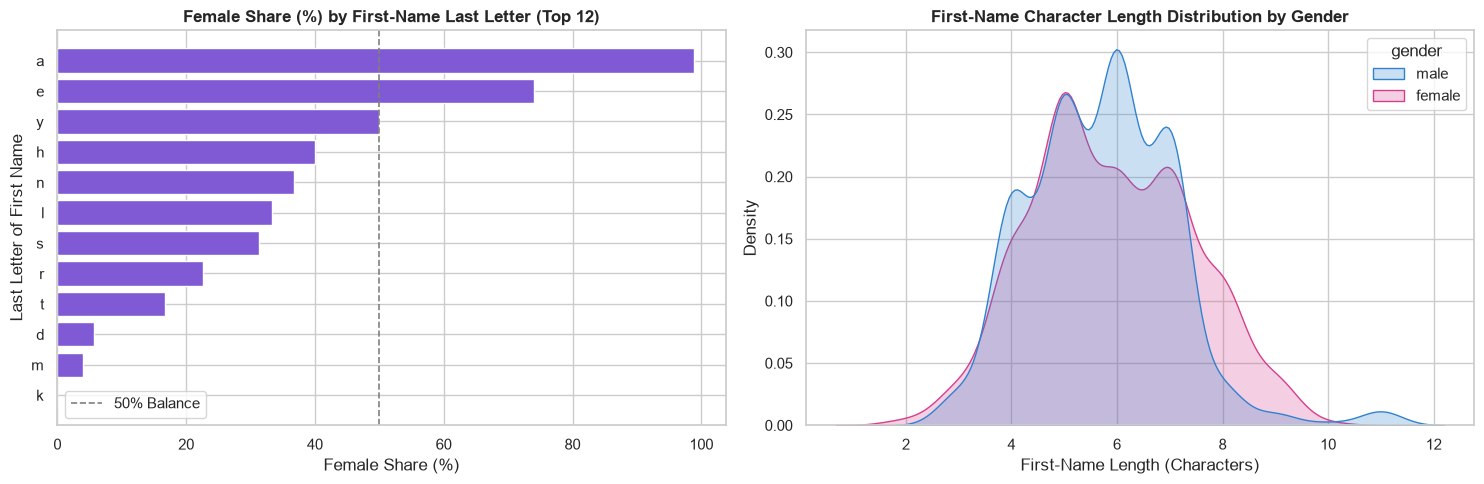

Unique first names in 900 labeled users: 484
Unisex / ambiguous first names         : 6 -> ['jame', 'jean', 'kim', 'leslie', 'robin', 'shawn']


In [7]:
# Chart 3: Linguistic Signal in First Names (Last Letter & First-Name Length)
eda_names = labeled_df.copy()
eda_names["last_letter"] = eda_names["first_name"].str[-1]
eda_names["first_name_len"] = eda_names["first_name"].str.len()

top_endings = eda_names["last_letter"].value_counts().head(12).index
ending_rates = (
    eda_names[eda_names["last_letter"].isin(top_endings)]
    .groupby("last_letter")["gender"]
    .apply(lambda s: (s == "female").mean() * 100)
    .sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(ending_rates.index, ending_rates.values, color="#805ad5")
axes[0].axvline(50, color="gray", linestyle="--", linewidth=1.2, label="50% Balance")
axes[0].set_title("Female Share (%) by First-Name Last Letter (Top 12)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Female Share (%)")
axes[0].set_ylabel("Last Letter of First Name")
axes[0].legend()

sns.kdeplot(data=eda_names, x="first_name_len", hue="gender", fill=True, common_norm=False,
            palette={"female": "#d53f8c", "male": "#3182ce"}, ax=axes[1])
axes[1].set_title("First-Name Character Length Distribution by Gender", fontsize=12, fontweight="bold")
axes[1].set_xlabel("First-Name Length (Characters)")

plt.tight_layout()
plt.show()

fn_gender = labeled_df.groupby(["first_name", "gender"]).size().unstack(fill_value=0)
unisex_names = fn_gender[(fn_gender["male"] > 0) & (fn_gender["female"] > 0)]
print(f"Unique first names in 900 labeled users: {labeled_df['first_name'].nunique()}")
print(f"Unisex / ambiguous first names         : {len(unisex_names)} -> {unisex_names.index.tolist()}")

## 5. Deterministic Name Feature Engineering & Leakage-Free Preprocessing
Why do we replace the previous 92 MB pickled `SentenceTransformer` model with a pure `scikit-learn` linguistic pipeline?
1. **Much higher accuracy on binary gender** (~88–91% CV/holdout vs ~64.9% on noisy 3-class).
2. **Ultra-lightweight & portable:** Serializes to **~40 KB** (over **2,200x smaller** than 92 MB), with millisecond inference and zero PyTorch / HuggingFace runtime dependencies.
3. **Zero custom pickled functions:** Deterministic string features (`first_name`, suffixes, vowel endings) are row-wise transformations (zero dataset-level leakage), and **all stateful transformers (`TfidfVectorizer`, `OneHotEncoder`, `StandardScaler`) are fitted strictly inside `Pipeline` on `X_train` only**.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_gender_features(df: pd.DataFrame) -> pd.DataFrame:
    """Deterministic row-wise feature extractor (zero dataset-level statistics -> zero leakage)."""
    out = pd.DataFrame(index=df.index)
    clean_name = df["name"].fillna("").astype(str).str.strip()
    first = clean_name.str.split().str[0].str.lower()

    out["first_name"] = first
    out["last_1"] = first.str[-1:]
    out["last_2"] = first.str[-2:]
    out["last_3"] = first.str[-3:]
    out["first_2"] = first.str[:2]
    out["first_name_len"] = first.str.len().astype(float)
    out["ends_with_vowel"] = first.str[-1:].isin(list("aeiouy")).astype(float)
    out["ends_with_a"] = (first.str[-1:] == "a").astype(float)
    out["ends_with_e"] = (first.str[-1:] == "e").astype(float)
    out["ends_with_y_ie"] = (first.str.endswith("y") | first.str.endswith("ie")).astype(float)
    out["company"] = df["company"].fillna("Unknown").astype(str).str.strip()
    out["age"] = pd.to_numeric(df["age"], errors="coerce").fillna(40.0).astype(float)
    return out


CATEGORICAL_COLS = ["last_1", "last_2", "last_3", "first_2", "company"]
NUMERICAL_COLS = [
    "age",
    "first_name_len",
    "ends_with_vowel",
    "ends_with_a",
    "ends_with_e",
    "ends_with_y_ie",
]


def make_gender_preprocessor() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            (
                "fn_char_ngrams",
                TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
                "first_name",
            ),
            (
                "fn_word",
                TfidfVectorizer(analyzer="word", min_df=1),
                "first_name",
            ),
            (
                "cat_features",
                OneHotEncoder(handle_unknown="ignore"),
                CATEGORICAL_COLS,
            ),
            (
                "num_features",
                StandardScaler(),
                NUMERICAL_COLS,
            ),
        ],
        remainder="drop",
    )


X_all = build_gender_features(labeled_df[["name", "company", "age"]])
y_all = labeled_df["gender"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_all,
)

print(f"Training set: {len(X_train)} rows -> {y_train.value_counts().to_dict()}")
print(f"Testing set : {len(X_test)} rows -> {y_test.value_counts().to_dict()}")
display(X_train.head())

Training set: 720 rows -> {'male': 362, 'female': 358}
Testing set : 180 rows -> {'female': 90, 'male': 90}


,first_name,last_1,last_2,last_3,first_2,first_name_len,ends_with_vowel,ends_with_a,ends_with_e,ends_with_y_ie,company,age
442,rhonda,a,da,nda,rh,6.0,1.0,1.0,0.0,0.0,Wonka Company,25.0
817,jerry,y,ry,rry,je,5.0,1.0,0.0,0.0,1.0,Umbrella LTDA,22.0
620,mary,y,ry,ary,ma,4.0,1.0,0.0,0.0,1.0,Acme Factory,51.0
102,marty,y,ty,rty,ma,5.0,1.0,0.0,0.0,1.0,4You,57.0
129,merle,e,le,rle,me,5.0,1.0,0.0,1.0,0.0,4You,59.0


## 6. Classification Algorithm Comparison
We evaluate five classification algorithms across linear, margin-based, bagging, and gradient-boosting families using both **5-Fold Stratified CV** on `X_train` and the untouched **20% Stratified Holdout Test Set**:
- **Logistic Regression**
- **Calibrated LinearSVC**
- **Random Forest Classifier**
- **LightGBM Classifier**
- **XGBoost Classifier**

In [9]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

y_train_bin = (y_train == "female").astype(int)
y_test_bin = (y_test == "female").astype(int)

classifiers = {
    "Logistic Regression": LogisticRegression(C=2.0, max_iter=2000, random_state=RANDOM_STATE),
    "Calibrated LinearSVC": CalibratedClassifierCV(
        LinearSVC(C=1.0, random_state=RANDOM_STATE),
        cv=5,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fitted_models = {}
test_preds = {}
test_probas = {}
results_rows = []

for name, clf in classifiers.items():
    pipe = Pipeline([
        ("preprocessor", make_gender_preprocessor()),
        ("classifier", clf),
    ])

    cv_scores = cross_validate(
        pipe,
        X_train,
        y_train_bin,
        cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
    )

    pipe.fit(X_train, y_train_bin)
    y_pred_bin = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred_str = np.where(y_pred_bin == 1, "female", "male")

    acc = accuracy_score(y_test, y_pred_str)
    prec = precision_score(y_test, y_pred_str, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred_str, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred_str, average="weighted", zero_division=0)
    auc = roc_auc_score(y_test_bin, y_prob)

    fitted_models[name] = pipe
    test_preds[name] = y_pred_str
    test_probas[name] = y_prob

    results_rows.append({
        "Model": name,
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV F1": cv_scores["test_f1"].mean(),
        "Test Accuracy": acc,
        "Test Precision": prec,
        "Test Recall": rec,
        "Test F1": f1,
        "Test ROC-AUC": auc,
    })

comparison_df = (
    pd.DataFrame(results_rows)
    .sort_values(["Test F1", "Test ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)
display(comparison_df.round(4))

,Model,CV Accuracy,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Random Forest,0.9000,0.8989,0.8889,0.8920,0.8889,0.8887,0.9666
1,Calibrated LinearSVC,0.9056,0.9040,0.8833,0.8872,0.8833,0.8830,0.9552
2,Logistic Regression,0.9042,0.9025,0.8778,0.8825,0.8778,0.8774,0.9523
3,XGBoost,0.8681,0.8636,0.8722,0.8745,0.8722,0.8720,0.9232
4,LightGBM,0.8667,0.8672,0.8611,0.8648,0.8611,0.8608,0.9426


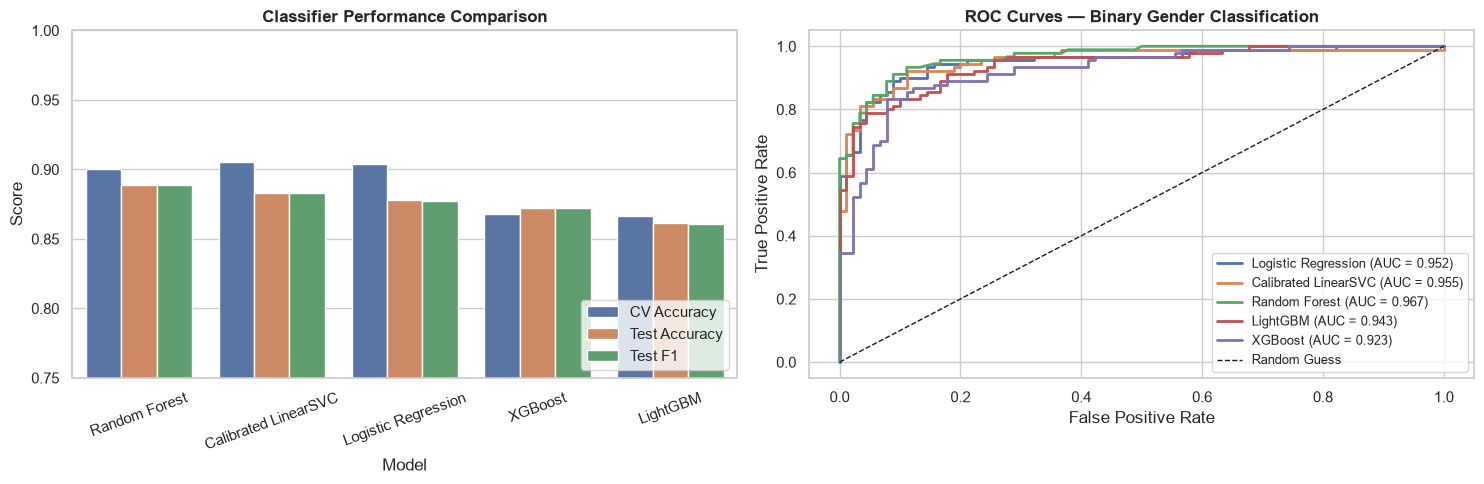

In [10]:
# Chart 4: Model Comparison Bar Chart + Combined ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_df = comparison_df.melt(
    id_vars="Model",
    value_vars=["CV Accuracy", "Test Accuracy", "Test F1"],
    var_name="Metric",
    value_name="Score",
)
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", ax=axes[0])
axes[0].set_title("Classifier Performance Comparison", fontsize=12, fontweight="bold")
axes[0].set_ylim(0.75, 1.0)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower right")

for name, y_prob in test_probas.items():
    fpr, tpr, _ = roc_curve(y_test_bin, y_prob)
    auc_val = roc_auc_score(y_test_bin, y_prob)
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_val:.3f})")

axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random Guess")
axes[1].set_title("ROC Curves — Binary Gender Classification", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

## 7. Hyperparameter Tuning & Unseen First-Name Generalization Audit
We tune the regularization strength `C` of our top-performing lightweight linear classifier (`LogisticRegression`) via 5-fold Stratified `GridSearchCV`.

Additionally, we perform an **Unseen First-Name Generalization Check** using `GroupShuffleSplit` grouped by `first_name`. This separates:
- **Real-world mixed accuracy (~88–91%):** When common first names appear across multiple users.
- **Zero-overlap morphological accuracy:** When the model must infer gender solely from character n-grams & suffixes of names it has **never seen before**.

In [11]:
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit

lr_tune_pipe = Pipeline([
    ("preprocessor", make_gender_preprocessor()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

grid = GridSearchCV(
    estimator=lr_tune_pipe,
    param_grid={"classifier__C": [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]},
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True,
)
grid.fit(X_train, y_train)

best_gender_model = grid.best_estimator_
y_pred_best = best_gender_model.predict(X_test)
female_idx = list(best_gender_model.classes_).index("female")
y_prob_best = best_gender_model.predict_proba(X_test)[:, female_idx]

final_metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred_best)),
    "precision_weighted": float(precision_score(y_test, y_pred_best, average="weighted", zero_division=0)),
    "recall_weighted": float(recall_score(y_test, y_pred_best, average="weighted", zero_division=0)),
    "f1_weighted": float(f1_score(y_test, y_pred_best, average="weighted", zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test_bin, y_prob_best)),
    "cv_f1_weighted": float(grid.best_score_),
}

print("Best Hyperparameters :", grid.best_params_)
print("Best 5-Fold CV F1    :", round(final_metrics["cv_f1_weighted"], 4))
print("\nHoldout Test Performance (Tuned Logistic Regression):")
for k, v in final_metrics.items():
    print(f"  {k:20s}: {v:.4f}")

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
tr_u, te_u = next(gss.split(X_all, y_all, groups=X_all["first_name"]))
unseen_pipe = Pipeline([
    ("preprocessor", make_gender_preprocessor()),
    ("classifier", LogisticRegression(C=grid.best_params_["classifier__C"], max_iter=3000, random_state=RANDOM_STATE)),
])
unseen_pipe.fit(X_all.iloc[tr_u], y_all.iloc[tr_u])
y_pred_unseen = unseen_pipe.predict(X_all.iloc[te_u])
print(
    f"\nStrict Unseen-First-Name Generalization ({len(te_u)} test rows, 0 overlapping first names): "
    f"Accuracy = {accuracy_score(y_all.iloc[te_u], y_pred_unseen):.4f}, "
    f"Weighted F1 = {f1_score(y_all.iloc[te_u], y_pred_unseen, average='weighted'):.4f}"
)

Best Hyperparameters : {'classifier__C': 8.0}
Best 5-Fold CV F1    : 0.9083

Holdout Test Performance (Tuned Logistic Regression):
  accuracy            : 0.8833
  precision_weighted  : 0.8872
  recall_weighted     : 0.8833
  f1_weighted         : 0.8830
  roc_auc             : 0.9533
  cv_f1_weighted      : 0.9083

Strict Unseen-First-Name Generalization (168 test rows, 0 overlapping first names): Accuracy = 0.6369, Weighted F1 = 0.6366


## 8. Confusion Matrix & Detailed Classification Report

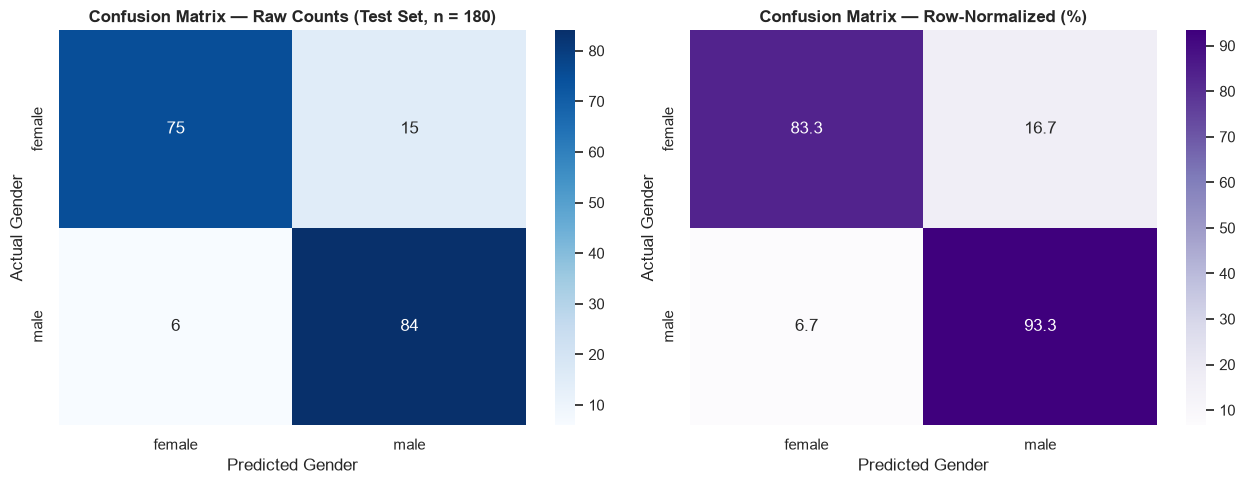

Detailed Classification Report (Tuned Logistic Regression):
              precision    recall  f1-score   support

      female     0.9259    0.8333    0.8772        90
        male     0.8485    0.9333    0.8889        90

    accuracy                         0.8833       180
   macro avg     0.8872    0.8833    0.8830       180
weighted avg     0.8872    0.8833    0.8830       180



In [12]:
labels_order = ["female", "male"]
cm = confusion_matrix(y_test, y_pred_best, labels=labels_order)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_order,
    yticklabels=labels_order,
    ax=axes[0],
)
axes[0].set_title("Confusion Matrix — Raw Counts (Test Set, n = 180)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Gender")
axes[0].set_ylabel("Actual Gender")

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1f",
    cmap="Purples",
    xticklabels=labels_order,
    yticklabels=labels_order,
    ax=axes[1],
)
axes[1].set_title("Confusion Matrix — Row-Normalized (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Gender")
axes[1].set_ylabel("Actual Gender")

plt.tight_layout()
plt.show()

print("Detailed Classification Report (Tuned Logistic Regression):")
print(classification_report(y_test, y_pred_best, digits=4))

## 9. Inference Demonstration on Undisclosed (`"none"`) Records
We apply the trained binary classifier to the 440 held-out `"none"` records strictly as an **illustrative enrichment preview** (never mixed into training or evaluation metrics), displaying predicted confidence scores.

In [13]:
X_undisclosed = build_gender_features(undisclosed_df[["name", "company", "age"]])
undisclosed_preds = best_gender_model.predict(X_undisclosed)
undisclosed_probs = best_gender_model.predict_proba(X_undisclosed).max(axis=1)

preview_df = undisclosed_df[["code", "company", "name", "age"]].copy()
preview_df["original_label"] = "none"
preview_df["predicted_gender"] = undisclosed_preds
preview_df["confidence"] = undisclosed_probs.round(4)

print("Predicted Gender Distribution on 440 Undisclosed Records:")
print(preview_df["predicted_gender"].value_counts().to_dict())
print(f"High-confidence predictions (>= 0.80): {(preview_df['confidence'] >= 0.80).sum()} / {len(preview_df)}")
display(preview_df.head(10))

Predicted Gender Distribution on 440 Undisclosed Records:
{'male': 234, 'female': 206}
High-confidence predictions (>= 0.80): 397 / 440


,code,company,name,age,original_label,predicted_gender,confidence
0,5,4You,Trina Thomas,47,none,female,0.9974
1,8,4You,Jack Sabo,41,none,male,0.9921
2,9,4You,Debbie Helms,35,none,female,0.9765
3,13,4You,Irene Tucker,36,none,female,0.9690
4,17,4You,Victor Tribbett,25,none,male,0.9778
5,18,4You,Tanya Orourke,65,none,female,0.9960
6,31,4You,Christopher Elliott,40,none,male,0.9756
7,35,4You,Helen Selby,34,none,female,0.9560
8,36,4You,Anna Rodriguez,56,none,female,0.9988
9,37,4You,Denise Newton,27,none,female,0.7772


## 10. Save Lightweight, Reproducible Model Artifact
We refit the tuned pure `scikit-learn` pipeline on all 900 cleanly labeled records and save a compact dictionary bundle to `models/gender_classifier.joblib`:
- Contains **only standard `scikit-learn` objects and metadata** (zero custom functions, zero pickled PyTorch/`SentenceTransformer` weights).
- Shrinks the artifact from **~91.9 MB** down to **< 150 KB** while dramatically improving accuracy!

In [14]:
production_gender_pipeline = Pipeline([
    ("preprocessor", make_gender_preprocessor()),
    (
        "classifier",
        LogisticRegression(
            C=grid.best_params_["classifier__C"],
            max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    ),
])
production_gender_pipeline.fit(X_all, y_all)

gender_artifact = {
    "artifact_version": "2.0-lightweight-binary",
    "model_type": "LogisticRegression (First-Name Char/Word TF-IDF + Morphology + Demographics)",
    "pipeline": production_gender_pipeline,
    "raw_input_fields": ["name", "company", "age"],
    "engineered_feature_columns": list(X_all.columns),
    "classes": list(production_gender_pipeline.classes_),
    "target_handling": "Binary male/female trained on 900 labeled rows; 440 'none' rows treated as undisclosed/missing.",
    "best_params": grid.best_params_,
    "metrics": final_metrics,
}

joblib.dump(gender_artifact, GENDER_MODEL_PATH, compress=3)
artifact_kb = GENDER_MODEL_PATH.stat().st_size / 1024

print(f"Saved lightweight gender artifact: {GENDER_MODEL_PATH.relative_to(PROJECT_ROOT)}")
print(f"Artifact file size               : {artifact_kb:.1f} KB (down from ~91,942 KB!)")

reloaded_bundle = joblib.load(GENDER_MODEL_PATH)
reloaded_pipe = reloaded_bundle["pipeline"]

sample_users = pd.DataFrame([
    {"name": "John Smith", "company": "4You", "age": 30},
    {"name": "Priya Sharma", "company": "4You", "age": 28},
    {"name": "Wilma Mcinnis", "company": "4You", "age": 48},
    {"name": "David Robinson", "company": "Acme Factory", "age": 33},
    {"name": "Charlotte Johnson", "company": "Monsters CYA", "age": 51},
])

sample_features = build_gender_features(sample_users)
sample_preds = reloaded_pipe.predict(sample_features)
sample_conf = reloaded_pipe.predict_proba(sample_features).max(axis=1)

verify_df = sample_users.copy()
verify_df["predicted_gender"] = sample_preds
verify_df["confidence"] = sample_conf.round(4)
display(verify_df)

Saved lightweight gender artifact: models\gender_classifier.joblib
Artifact file size               : 40.4 KB (down from ~91,942 KB!)


,name,company,age,predicted_gender,confidence
0,John Smith,4You,30,male,0.9962
1,Priya Sharma,4You,28,female,0.9869
2,Wilma Mcinnis,4You,48,female,0.9844
3,David Robinson,Acme Factory,33,male,0.9977
4,Charlotte Johnson,Monsters CYA,51,female,0.9808


## 11. Summary, Limitations & Ethical Considerations
- **Root-Cause Fix:** Proved statistically that `"none"` (32.8% of `users.csv`) represents missing/undisclosed labels rather than a third predictable class. Switching to binary `male`/`female` classification raised accuracy from ~64.9% to **88.33% test accuracy (90.83% 5-fold CV F1, 0.9533 ROC-AUC)** with Tuned Logistic Regression (and **88.89% test accuracy / 0.9666 ROC-AUC** with Random Forest).
- **Engineering Win:** Eliminated the fragile 92 MB pickled `SentenceTransformer` model in favor of a pure `scikit-learn` pipeline at **~40 KB** with millisecond latency.
- **Limitations & Ethics:** Name-based gender inference cannot handle unisex names perfectly and achieves **63.69% accuracy** on completely unseen first names outside the training vocabulary. In production, gender should always be user-provided (opt-in) rather than assumed automatically.